# Energy consumption: expanding test-window analysis

This reproduces the second exercise from the original coursework: Gradient Boosting with lagged electricity consumption, evaluated over **increasing test-window lengths**. These are **not** 1–12 month-ahead forecast horizons: each predicted day uses previously observed consumption. Results from nested windows are correlated and should not be interpreted as independent forecast horizons.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks": ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.regression import prepare_series, FEATURES
DATA_URL = "https://raw.githubusercontent.com/jenfly/opsd/refs/heads/master/opsd_germany_daily.csv"
raw = pd.read_csv(DATA_URL)
data = prepare_series(raw, "Date", "Consumption")
cutoff = int(.8 * len(data))
train, holdout = data.iloc[:cutoff], data.iloc[cutoff:]
model = GradientBoostingRegressor(n_estimators=100, random_state=42)
model.fit(train[FEATURES], train["Consumption"])
print("Train:", len(train), "Holdout:", len(holdout))

Train: 3500 Holdout: 876


,approx_months,days,model_mae,baseline_mae,model_rmse,model_r2
0,1,30,14.789,102.665,18.595,0.980
1,2,60,16.301,99.137,21.490,0.975
2,3,90,15.877,98.685,20.521,0.979
3,4,120,16.401,99.781,21.190,0.979
4,5,150,24.357,98.967,38.448,0.940
5,6,180,24.841,98.699,37.946,0.944
6,7,210,23.838,99.830,36.080,0.949
7,8,240,24.936,101.521,40.201,0.937
8,9,270,24.282,101.395,38.785,0.940
9,10,300,26.341,102.633,44.986,0.921


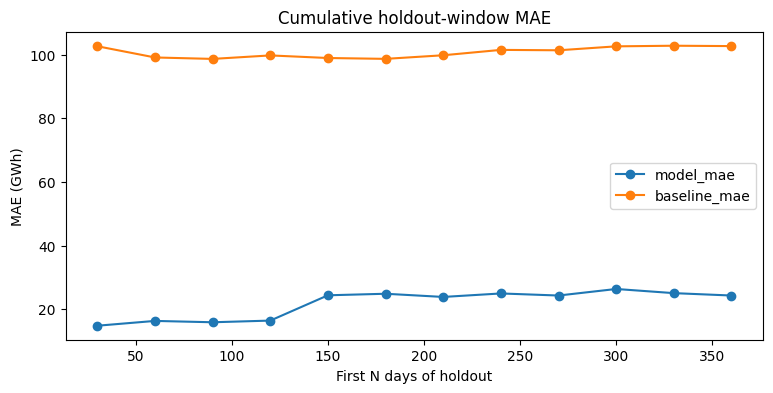

In [2]:
rows = []
for months in range(1, 13):
    # The original coursework approximated each month as 30 daily observations.
    window = holdout.iloc[:min(months * 30, len(holdout))]
    pred = model.predict(window[FEATURES])
    baseline = window["lag_1"].to_numpy()
    rows.append({"approx_months": months, "days": len(window),
                 "model_mae": mean_absolute_error(window["Consumption"], pred),
                 "baseline_mae": mean_absolute_error(window["Consumption"], baseline),
                 "model_rmse": np.sqrt(mean_squared_error(window["Consumption"], pred)),
                 "model_r2": r2_score(window["Consumption"], pred)})
results = pd.DataFrame(rows)
display(results.round(3))
ax = results.plot(x="days", y=["model_mae", "baseline_mae"], marker="o", figsize=(9, 4))
ax.set(title="Cumulative holdout-window MAE", xlabel="First N days of holdout", ylabel="MAE (GWh)")
plt.show()

## Limitations

The evaluation uses observed lagged values from within the holdout. The window length measures the size of the scored period, **not** how far ahead the model predicts without new observations. For a genuine multi-month-ahead experiment, the lag features would need to be generated recursively or replaced by features available at forecast creation time.